# Profile-wise analysis code adapted from "Making Predictions Using Poorly Identified Mathematical Models" by Matthew J. Simpson & Oliver J. Maclaren 

## Original profile-wise analysis code avaliable here: https://github.com/ProfMJSimpson/NonidentifiableWorkflow

In [1]:
#load packages 
using DifferentialEquations
using Interpolations
using Random
using Distributions
using Roots
using NLopt
using JLD
using FileIO
using Plots; pyplot()
logocolors = Colors.JULIA_LOGO_COLORS

(red = RGB{N0f8}(0.796,0.235,0.2), green = RGB{N0f8}(0.22,0.596,0.149), blue = RGB{N0f8}(0.251,0.388,0.847), purple = RGB{N0f8}(0.584,0.345,0.698))

In [2]:
#define parameters
number_of_tumors = 55
number_of_samples = 2000
chain_runs = 4
number_of_parameters = 3

big_chain = zeros(number_of_samples.*chain_runs,number_of_parameters+1,number_of_tumors)
for i = 1:number_of_tumors
    big_chain[:,:,i] = load("/Users/jessekre/Dropbox/julia/MDSC_lung_mets_automated_v2/chain_array$i.jld")["data"]
end

tumor_number = 1

1

## Profile-wise analysis on simulated data for just tumor population

In [3]:
#simulated data time
t = 0.0:1.0:300.0

0.0:1.0:300.0

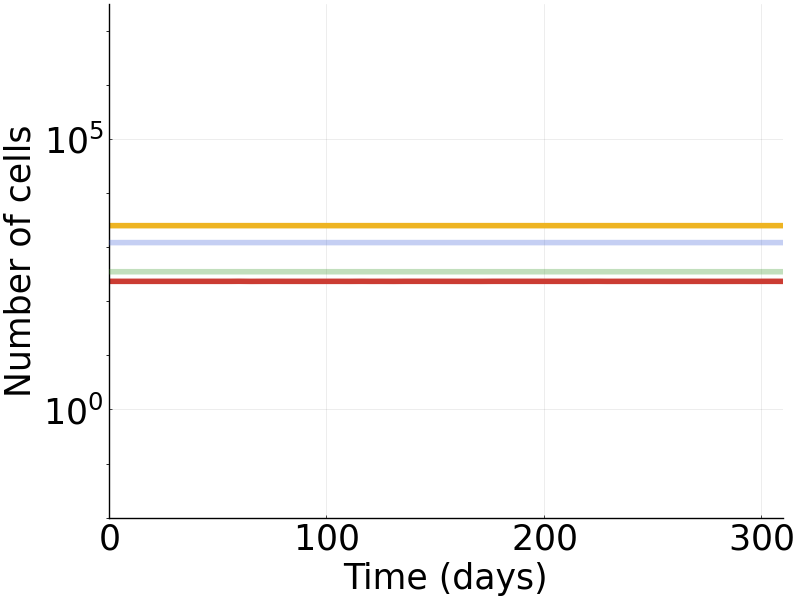

In [4]:
#set numerical solution algorithm
alg = Tsit5()

#define condition for simulation to end
function condition(u,t,integrator) 
  u[1] < 0.0 || u[2] < 0.0 || u[3] < 0.0 || u[4] < 0.0
end

floor_event = DiscreteCallback(condition, terminate!)

#define model without delay
function ode_system(du,u,p,t)
    T,MDSC,NK,CTL = u
    β₃, β₄, α₆ = p
    
# Cancer cells (tumor)
    du[1] = dT = α₁*T*log(max(η/T,1)) - β₁*T*NK - β₂*T*CTL - ζ₁*T
 # MDSCs 
    du[2] = dMDSC = α₂ + α₃*T/(γ₁+(T)) - ζ₂*MDSC 
 # NK cells
    du[3] = dNK = α₄ + α₅*(T^2)/(γ₂+(T^2)) - β₃*MDSC*NK - ζ₃*NK 
 # CTL cells
    du[4] = dCTL = α₆*T*NK + α₇*(T^2)/(γ₃+(T^2)) - β₄*MDSC*CTL - ζ₄*CTL
end

#set model parameters
α₂ = 5.0*(10.0^2.0) #MDSCs production rate
α₃ = (10.0^8.0) #MDSCs expansion coefficient 
ζ₂ = 0.2 #MDSCs death rate

α₁ = 10.0^(-1.0) #tumor growth rate
η = 10.0^7.0 #tumor maximum size
β₁ = 6.0*(10.0^(-4.0)) #tumor cells kill rate by NK cells
β₂ = 7.0*(10.0^(-4.0)) #tumor cells kill rate by T cells
ζ₁ = 0.0 #tumor cell death rate

α₄ = 5.0*(10.0^1.0) #NK cells production rate
α₅ = 2.5*(10.0^(-2.0)) #NK cells expansion coefficient
β₃ = 4*(10.0^(-5.0)) #NK cells inactivation rate by MDSCs
ζ₃ = 4.12*(10.0^(-2.0)) #NK cells death rate

α₆ = 4.0*(10.0^(-3.0)) #CTL stimulation as a result of tumor-NK cell interaction
α₇ = 10.0^(-1.0) #CTL expansion coefficient 
β₄ = (10.0^(-4.0)) #CTL inactivation rate by MDSCs
ζ₄ = 2.0*(10.0^(-2.0)) #CTL death rate

γ₁ = (10.0^(10.0)) #steepness coefficient of MDSC production curve
γ₂ = 2.02*(10.0^(7.0)) #steepness coefficient of NK production curve
γ₃ = 2.02*(10.0^(7.0)) #steepness coefficient of CTL production curve

parameters = [β₃, β₄, α₆]

p = parameters

tspan = (0.0,last(t).+10)
u0 = [234.52607557161835;2511.7148454521493;352.93622128903235;1219.5854955705156]

prob1 = ODEProblem(ode_system,u0,tspan,p)
sol = solve(prob1,alg,saveat=0.1,callback=floor_event)
plot(sol, lw = 4, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)

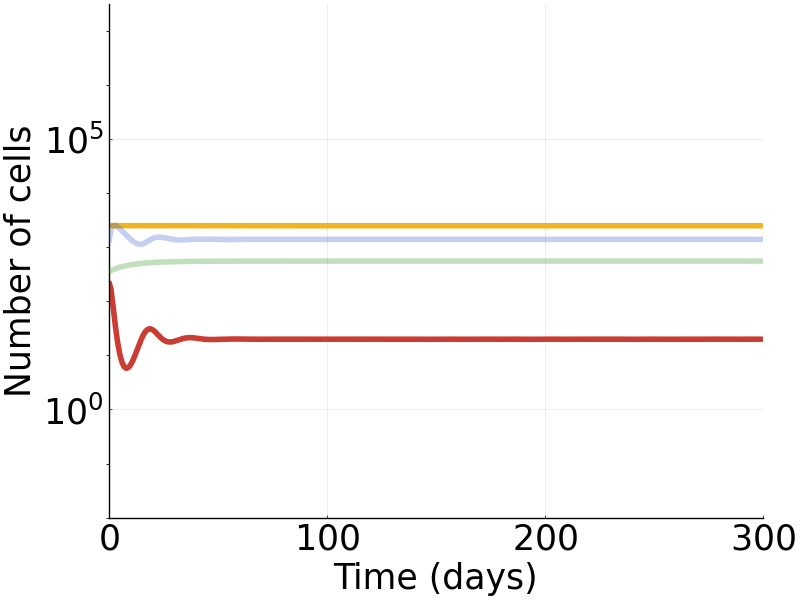

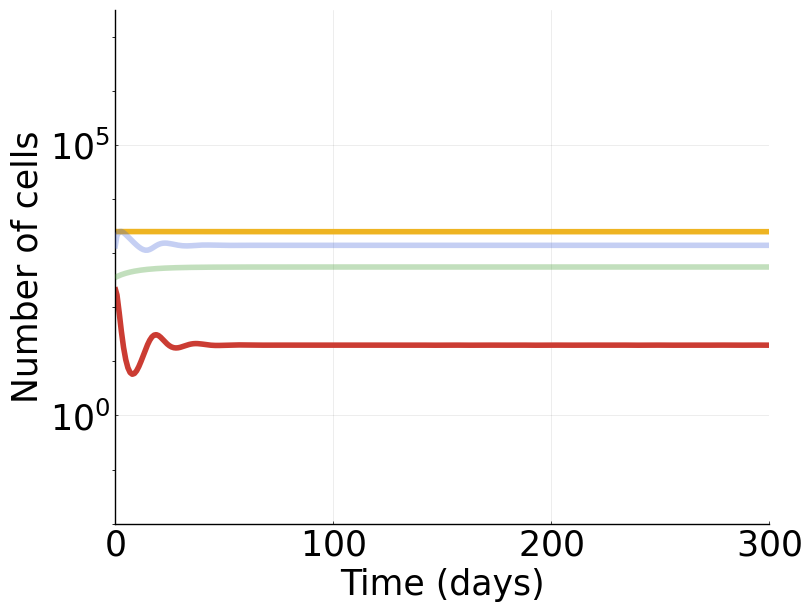

301-element Vector{Float64}:
  0.0
 -0.2837587657928555
 -0.6593852288816521
 -0.8469455615806265
 -0.9227817632625074
 -0.9539954290244597
 -0.9676135246233967
 -0.9735080041093276
 -0.9753675406292808
 -0.9745547185028195
 -0.9714386911416173
 -0.9658878734667841
 -0.9575187357091078
  ⋮
 -0.9149453565208391
 -0.9148905636914384
 -0.9148453264319024
 -0.9148087644477849
 -0.914793437473377
 -0.9148055818331727
 -0.9148451104418687
 -0.9149056128043646
 -0.914974355015763
 -0.915032279761369
 -0.9150584209525149
 -0.9150776667686695

In [5]:
#simulated data
β₃ = median(big_chain[:,1,tumor_number])
β₄ = median(big_chain[:,2,tumor_number])
α₆ = median(big_chain[:,3,tumor_number])
parameters = [β₃, β₄, α₆]
p = parameters
prob1 = ODEProblem(ode_system,u0,tspan,p)
sol = solve(prob1,alg,saveat=t,callback=floor_event)
display(plot(sol, lw = 4, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25))
data = zeros(length(t))
for step = 2:length(t)
    data[step] = (sol.u[step,1][1]-u0[1])./u0[1]
end
data[1] = 0.0
data

In [6]:
simulated_noise = zeros(length(t))
for i = 2:length(t)
    simulated_noise[i] = rand(Normal(0,0.05))
end

data = data .+ simulated_noise

301-element Vector{Float64}:
  0.0
 -0.20349922994947384
 -0.6999888609594391
 -0.750869956745993
 -0.9050639188516423
 -0.9914519904720585
 -0.9632804330595237
 -0.9505980672487888
 -0.9756451444150425
 -0.9638287949379177
 -1.0216817594657812
 -1.018252398761868
 -1.019320478345997
  ⋮
 -0.9428582354289644
 -0.9193583001173413
 -0.9067996254968976
 -0.8421666914577149
 -0.9862302551131658
 -0.9038717454712953
 -0.9123263546613913
 -0.8166444492015487
 -0.8492002232477738
 -0.9725349242321202
 -1.023494856533548
 -0.9737468295835677

In [7]:
gr()
a=zeros(3)
β₃ = mean(big_chain[:,1,tumor_number])
β₄ = mean(big_chain[:,2,tumor_number])
α₆ = mean(big_chain[:,3,tumor_number])
tt=0:0.01:last(tspan)

0.0:0.01:310.0

In [8]:
#function to evaluate the loglikelihood 
function loglhood(data,a)
    σ=0.05
    y=zeros(length(t))
    prob1 = ODEProblem(ode_system,u0,tspan,a)
    sol = solve(prob1,alg,saveat=t,callback=floor_event)
    for step = 2:length(t)
        y[step] = (sol.u[step,1][1]-u0[1])./u0[1]
    end
    y[1] = 0.0
    e=0;
    dist=Normal(0,σ);
    e=loglikelihood(dist,data-y) 
    return sum(e)
end

loglhood (generic function with 1 method)

In [9]:
#define simple parameter bounds
beta_three_min=10.0^(-7.0)
beta_three_max=10.0^(-2.0)
beta_four_min=10.0^(-7.0)
beta_four_max=10.0^(-2.0)
alpha_six_min=10.0^(-5.0)
alpha_six_max=10.0^(-1.0)

0.1

In [10]:
#optimize function
function Optimise(fun,θ₀,lb,ub)
    tomax=(θ,∂θ)->fun(θ)
    opt=Opt(:LN_BOBYQA,length(θ₀))
    opt.max_objective=tomax
    opt.lower_bounds=lb      
    opt.upper_bounds=ub
    opt.maxtime=1*60
    res = optimize(opt,θ₀)
    return res[[2,1]]

end

Optimise (generic function with 1 method)

In [11]:
#function to be optimized for MLE
a=zeros(3)
function funmle(a)
return loglhood(data,a)
end

funmle (generic function with 1 method)

In [12]:
#find MLE by numerical optimisation, visually compare data and MLE solution
θG = [β₃,β₄,α₆]
lb=[beta_three_min,beta_four_min,alpha_six_min]
ub=[beta_three_max,beta_four_max,alpha_six_max]
(xopt,fopt)  = Optimise(funmle,θG,lb,ub)
fmle=fopt
beta_three_mle=xopt[1]; 
beta_four_mle = xopt[2];
alpha_six_mle=xopt[3]; 

ymle=zeros(4, length(tt))
prob1 = ODEProblem(ode_system,u0,tspan,[beta_three_mle,beta_four_mle,alpha_six_mle])
sol_long = solve(prob1,alg,saveat=tt,callback=floor_event)
for step = 2:length(tt)
    ymle[:,step] = (sol_long.u[step,1][:].-u0[:])./u0[:]
end
ymle[:,1] .= 0.0


p1=plot(tt,ymle[1,:],color = logocolors.red,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[2,:],color = "goldenrod2",xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[3,:],alpha = 0.3, color = logocolors.green,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[4,:],alpha = 0.3, color = logocolors.blue,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.2), xtickfontsize=16,ytickfontsize=16, xguidefontsize = 18, yguidefontsize = 18, font = "Ariel") #-1.2,3.6

p1=scatter!(t,data[:],legend=false,msw=0,ms=5,color=logocolors.red,msa=:darkorange, alpha = 0.5)
display(p1)

In [13]:
M = 100

100

In [14]:
#decreasing tumor parameters bounds for visualization
beta_three_min= 10.0^(-6.0)
beta_three_max= 10.0^(-4.0)
beta_four_min= 10.0^(-6.0)
beta_four_max= 10.0^(-4.0)
alpha_six_min= 10.0^(-5.0)
alpha_six_max= 10.0^(-1.0)

#increasing tumor parameters bounds for visualization
#beta_three_min= 10.0^(-5.0)
#beta_three_max= 10.0^(-3.0)
#beta_four_min= 10.0^(-5.0)
#beta_four_max= 10.0^(-3.0)
#alpha_six_min= 10.0^(-3.0)
#alpha_six_max= 10.0^(-1.0)

0.1

In [15]:
df=1
llstar=-quantile(Chisq(df),0.95)/2
#function to define univariate profile for λ    
function univariate3(β₃)
a=zeros(2)    
function fun3(a)
return loglhood(data,[β₃,a[1],a[2]])
end
θG=[beta_four_mle,alpha_six_mle]
lb=[beta_four_min,alpha_six_min] 
ub=[beta_four_max,alpha_six_max] 
(xopt,fopt)=Optimise(fun3,θG,lb,ub)
return fopt,xopt
end 
f(x) = univariate3(x)[1]

f (generic function with 1 method)

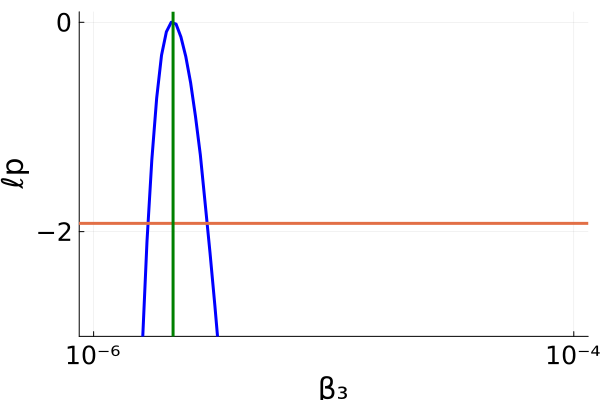

In [16]:
#take a grid of M points to plot the univariate profile likelihood
beta_three_range=LinRange(beta_three_min,beta_three_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate3(beta_three_range[i])[1]
end

r1=plot(beta_three_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r1=hline!([llstar],lw=3)
r1=vline!([beta_three_mle], legend=false,xlabel="β₃",ylabel="ℓp",lw=3,color=:green, yticks = [0,-2],xticks = ([beta_three_min,beta_three_max],["10⁻⁶","10⁻⁴"]),  xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

In [17]:
function univariate4(β₄)
    a=zeros(2)    
    function fun4(a)
    return loglhood(data,[a[1],β₄,a[2]])
    end
    θG=[beta_three_mle,alpha_six_mle]
    lb=[beta_three_min,alpha_six_min] 
    ub=[beta_three_max,alpha_six_max] 
    (xopt,fopt)=Optimise(fun4,θG,lb,ub)
    return fopt,xopt
    end 
    f(x) = univariate4(x)[1]

f (generic function with 1 method)

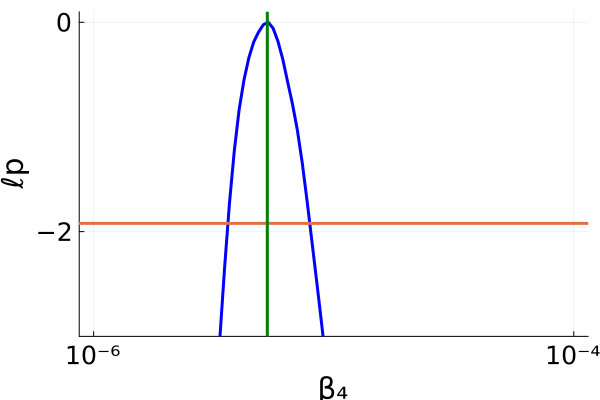

In [18]:
beta_four_range=LinRange(beta_four_min,beta_four_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate4(beta_four_range[i])[1]
end

r2=plot(beta_four_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r2=hline!([llstar],lw=3)
r2=vline!([beta_four_mle], legend=false,xlabel="β₄",ylabel="ℓp",lw=3,color=:green,yticks = [0,-2],xticks = ([beta_four_min,beta_four_max],["10⁻⁶","10⁻⁴"]), xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

In [19]:
function univariate6(α₆)
    a=zeros(2)    
    function fun6(a)
    return loglhood(data,[a[1],a[2],α₆])
    end
    θG=[beta_three_mle,beta_four_mle]
    lb=[beta_three_min,beta_four_min] 
    ub=[beta_three_max,beta_four_max] 
    (xopt,fopt)=Optimise(fun6,θG,lb,ub)
    return fopt,xopt
    end 
    f(x) = univariate6(x)[1]

f (generic function with 1 method)

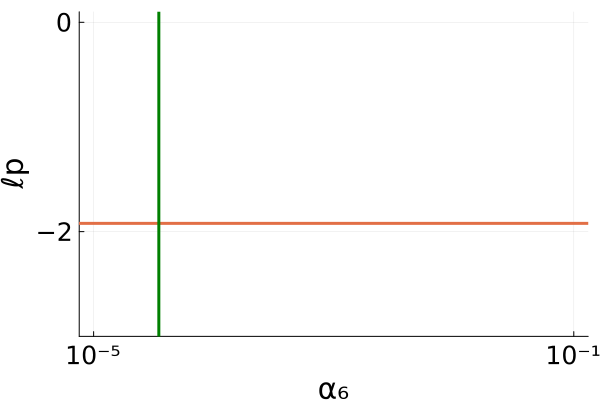

In [20]:
alpha_six_range=LinRange(alpha_six_min,alpha_six_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate6(alpha_six_range[i])[1]
end

r3=plot(alpha_six_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r3=hline!([llstar],lw=3)
r3=vline!([alpha_six_mle],legend=false,xlabel="α₆",ylabel="ℓp",lw=3,color=:green,yticks = [0,-2],xticks = ([alpha_six_min,alpha_six_max],["10⁻⁵","10⁻¹"]),xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

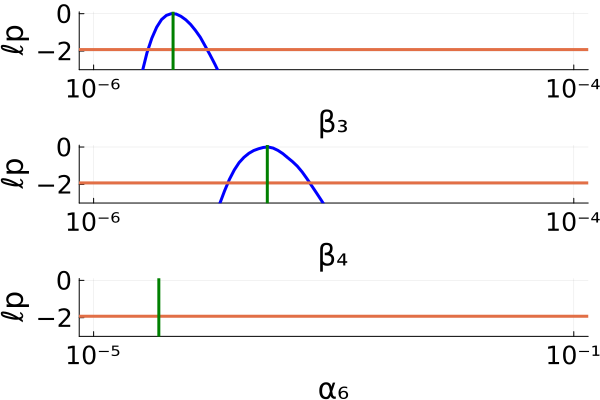

In [21]:
r4=plot(r1,r2,r3,layout=(3,1))
display(r4)

## Profile-wise analysis on simulated data for all model populations

In [22]:
#simulated data time
t = 0.0:1.0:300.0

0.0:1.0:300.0

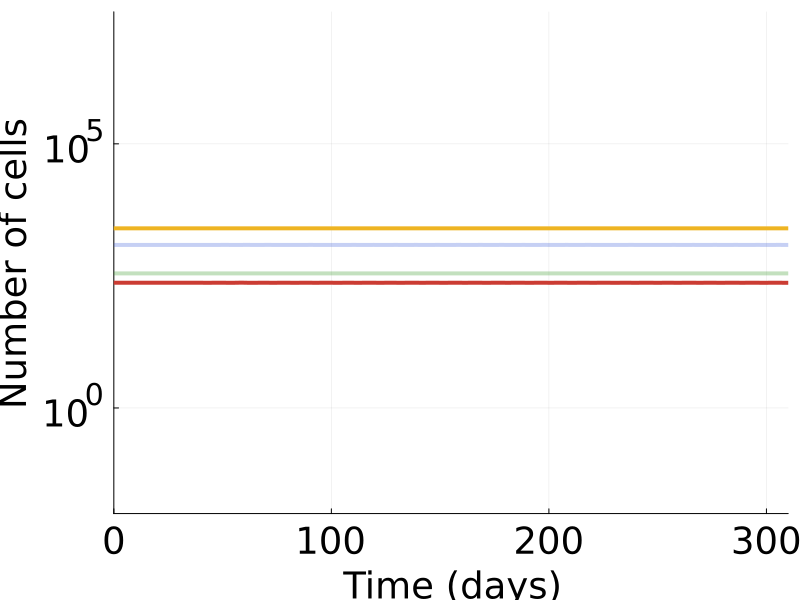

In [23]:
#set numerical solution algorithm
alg = Tsit5()

#define condition for simulation to end
function condition(u,t,integrator) 
  u[1] < 0.0 || u[2] < 0.0 || u[3] < 0.0 || u[4] < 0.0
end

floor_event = DiscreteCallback(condition, terminate!)

#define model without delay
function ode_system(du,u,p,t)
    T,MDSC,NK,CTL = u
    β₃, β₄, α₆ = p
    
# Cancer cells (tumor)
    du[1] = dT = α₁*T*log(max(η/T,1)) - β₁*T*NK - β₂*T*CTL - ζ₁*T
 # MDSCs 
    du[2] = dMDSC = α₂ + α₃*T/(γ₁+(T)) - ζ₂*MDSC 
 # NK cells
    du[3] = dNK = α₄ + α₅*(T^2)/(γ₂+(T^2)) - β₃*MDSC*NK - ζ₃*NK 
 # CTL cells
    du[4] = dCTL = α₆*T*NK + α₇*(T^2)/(γ₃+(T^2)) - β₄*MDSC*CTL - ζ₄*CTL
end

#set model parameters
α₂ = 5.0*(10.0^2.0) #MDSCs production rate
α₃ = (10.0^8.0) #MDSCs expansion coefficient 
ζ₂ = 0.2 #MDSCs death rate

α₁ = 10.0^(-1.0) #tumor growth rate
η = 10.0^7.0 #tumor maximum size
β₁ = 6.0*(10.0^(-4.0)) #tumor cells kill rate by NK cells
β₂ = 7.0*(10.0^(-4.0)) #tumor cells kill rate by T cells
ζ₁ = 0.0 #tumor cell death rate

α₄ = 5.0*(10.0^1.0) #NK cells production rate
α₅ = 2.5*(10.0^(-2.0)) #NK cells expansion coefficient
β₃ = 4*(10.0^(-5.0)) #NK cells inactivation rate by MDSCs
ζ₃ = 4.12*(10.0^(-2.0)) #NK cells death rate

α₆ = 4.0*(10.0^(-3.0)) #CTL stimulation as a result of tumor-NK cell interaction
α₇ = 10.0^(-1.0) #CTL expansion coefficient 
β₄ = (10.0^(-4.0)) #CTL inactivation rate by MDSCs
ζ₄ = 2.0*(10.0^(-2.0)) #CTL death rate

γ₁ = (10.0^(10.0)) #steepness coefficient of MDSC production curve
γ₂ = 2.02*(10.0^(7.0)) #steepness coefficient of NK production curve
γ₃ = 2.02*(10.0^(7.0)) #steepness coefficient of CTL production curve

parameters = [β₃, β₄, α₆]

p = parameters

tspan = (0.0,last(t).+10)
u0 = [234.52607557161835;2511.7148454521493;352.93622128903235;1219.5854955705156]

prob1 = ODEProblem(ode_system,u0,tspan,p)
sol = solve(prob1,alg,saveat=0.1,callback=floor_event)
plot(sol, lw = 4, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25)

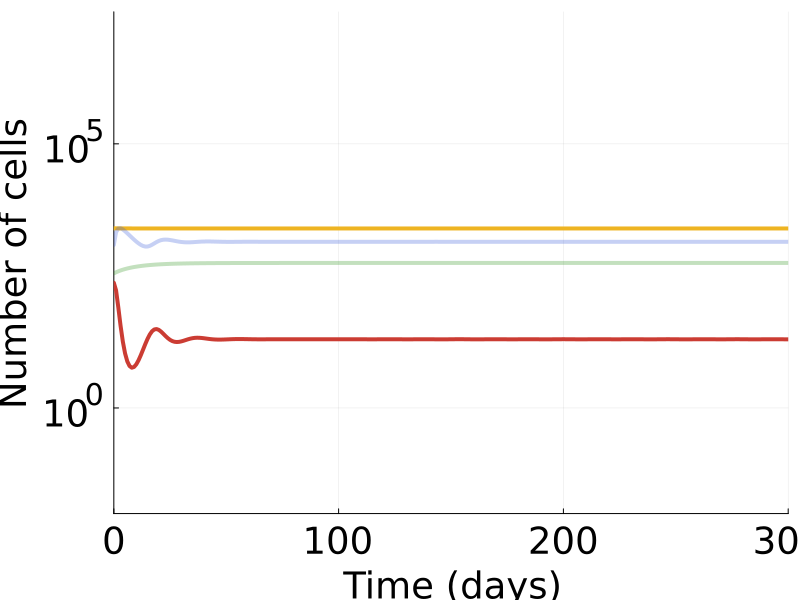

4×301 Matrix{Float64}:
 0.0  -0.283759    -0.659385     -0.846946    …  -0.915058    -0.915078
 0.0  -9.20302e-5  -0.000491031  -0.00105262     -0.00426698  -0.00426712
 0.0   0.0492531    0.0942721     0.135436        0.574896     0.574896
 0.0   0.740612     1.05869       1.07408         0.147046     0.146815

In [24]:
#simulated data
β₃ = median(big_chain[:,1,tumor_number])
β₄ = median(big_chain[:,2,tumor_number])
α₆ = median(big_chain[:,3,tumor_number])
parameters = [β₃, β₄, α₆]
p = parameters
prob1 = ODEProblem(ode_system,u0,tspan,p)
sol = solve(prob1,alg,saveat=t,callback=floor_event)
display(plot(sol, lw = 4, yaxis=:log,size =(1600/2,600), font = "Ariel", ylims = (0.01,10^7.5), color = [logocolors.red "goldenrod2" logocolors.green logocolors.blue], alpha = [1 1 0.3 0.3], legend = false, xtickfontsize=25,ytickfontsize=25,xlabel="Time (days)",xguidefontsize=25,ylabel="Number of cells",yguidefontsize=25,title = "",titlefontsize=25))
data = zeros(4,length(t))
for step = 2:length(t)
    data[:,step] = (sol.u[step,1][:].-u0[:])./u0[:]
end
data[:,1] .= 0.0
data

In [25]:
simulated_noise = zeros(4,length(t))
for i = 2:length(t)
    for j = 1:4
        simulated_noise[j,i] = rand(Normal(0,0.05))
    end
end

data = data .+ simulated_noise

4×301 Matrix{Float64}:
 0.0  -0.34412    -0.549311     …  -0.92018    -0.941984   -0.964218
 0.0   0.0883533  -0.000397805     -0.0661284   0.0337258  -0.0738124
 0.0   0.0544427   0.162674         0.611811    0.597132    0.579938
 0.0   0.718144    1.05178          0.166098    0.138488    0.111514

In [26]:
gr()
a=zeros(3)
β₃ = mean(big_chain[:,1,tumor_number])
β₄ = mean(big_chain[:,2,tumor_number])
α₆ = mean(big_chain[:,3,tumor_number])
tt=0:0.01:last(tspan)

0.0:0.01:310.0

In [27]:
#function to evaluate the loglikelihood 
function loglhood(data,a)
    σ=0.05
    y=zeros(4,length(t))
    prob1 = ODEProblem(ode_system,u0,tspan,a)
    sol = solve(prob1,alg,saveat=t,callback=floor_event)
    for step = 2:length(t)
        y[:,step] = (sol.u[step,1][:].-u0[:])./u0[:]
    end
    y[:,1] .= 0.0
    e=0;
    dist=Normal(0,σ);
    e=loglikelihood(dist,data-y) 
    return sum(e)
end

loglhood (generic function with 1 method)

In [28]:
#define simple parameter bounds,
beta_three_min=10.0^(-7.0)
beta_three_max=10.0^(-2.0)
beta_four_min=10.0^(-7.0)
beta_four_max=10.0^(-2.0)
alpha_six_min=10.0^(-5.0)
alpha_six_max=10.0^(-1.0)

0.1

In [29]:
#optimize function
function Optimise(fun,θ₀,lb,ub)    
    tomax=(θ,∂θ)->fun(θ)
    opt=Opt(:LN_BOBYQA,length(θ₀))
    opt.max_objective=tomax
    opt.lower_bounds=lb      
    opt.upper_bounds=ub
    opt.maxtime=1*60
    res = optimize(opt,θ₀)
    return res[[2,1]]

end

Optimise (generic function with 1 method)

In [30]:
#function to be optimized for MLE
a=zeros(3)
function funmle(a)
return loglhood(data,a)
end

funmle (generic function with 1 method)

In [31]:
#find MLE by numerical optimisation, visually compare data and MLE solution
θG = [β₃,β₄,α₆]
lb=[beta_three_min,beta_four_min,alpha_six_min]
ub=[beta_three_max,beta_four_max,alpha_six_max]
(xopt,fopt)  = Optimise(funmle,θG,lb,ub)
fmle=fopt
beta_three_mle=xopt[1]; 
beta_four_mle = xopt[2];
alpha_six_mle=xopt[3]; 

ymle=zeros(4, length(tt))
prob1 = ODEProblem(ode_system,u0,tspan,[beta_three_mle,beta_four_mle,alpha_six_mle])
sol_long = solve(prob1,alg,saveat=tt,callback=floor_event)
for step = 2:length(tt)
    ymle[:,step] = (sol_long.u[step,1][:].-u0[:])./u0[:]
end
ymle[:,1] .= 0.0

p1=plot(tt,ymle[1,:],color = logocolors.red,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[2,:],color = "goldenrod2",xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[3,:],alpha = 0.3,color = logocolors.green,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,3.6)) #-1.2,3.6
p1=plot!(tt,ymle[4,:],alpha = 0.3,color = logocolors.blue,xlabel="Time",ylabel="Relative change",legend=false,lw=4,xlims=(0,last(tspan)),ylims=(-1.2,1.2), xtickfontsize=16,ytickfontsize=16, xguidefontsize = 18, yguidefontsize = 18, font = "Ariel") #-1.2,3.6

p1=scatter!(t,data[1,:],legend=false,msw=0,ms=5,color=logocolors.red,msa=:darkorange, alpha = 0.5)
p1=scatter!(t,data[2,:],legend=false,msw=0,ms=5,color="goldenrod2",msa=:darkorange, alpha = 0.5)
p1=scatter!(t,data[3,:],legend=false,msw=0,ms=5,color=logocolors.green,msa=:darkorange, alpha = 0.15)
p1=scatter!(t,data[4,:],legend=false,msw=0,ms=5,color=logocolors.blue,msa=:darkorange, alpha = 0.15)

display(p1)

In [32]:
M = 100

100

In [33]:
#decreasing tumor parameters bounds for visualization
beta_three_min= 10.0^(-6.0)
beta_three_max= 10.0^(-4.0)
beta_four_min= 10.0^(-6.0)
beta_four_max= 10.0^(-4.0)
alpha_six_min= 10.0^(-5.0)
alpha_six_max= 10.0^(-1.0)

#increasing tumor parameters bounds for visualization
#beta_three_min= 10.0^(-5.0)
#beta_three_max= 10.0^(-3.0)
#beta_four_min= 10.0^(-5.0)
#beta_four_max= 10.0^(-3.0)
#alpha_six_min= 10.0^(-3.0)
#alpha_six_max= 10.0^(-1.0)

0.1

In [34]:
df=1
llstar=-quantile(Chisq(df),0.95)/2
#function to define univariate profile for λ    
function univariate3(β₃)
a=zeros(2)    
function fun3(a)
return loglhood(data,[β₃,a[1],a[2]])
end
θG=[beta_four_mle,alpha_six_mle]
lb=[beta_four_min,alpha_six_min] 
ub=[beta_four_max,alpha_six_max] 
(xopt,fopt)=Optimise(fun3,θG,lb,ub)
return fopt,xopt
end 
f(x) = univariate3(x)[1]

f (generic function with 1 method)

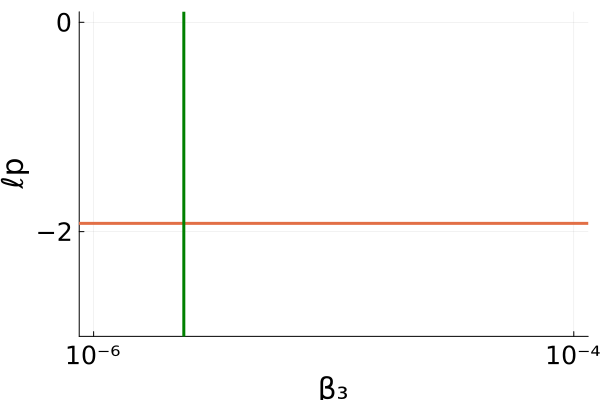

In [35]:
#take a grid of M points to plot the univariate profile likelihood

beta_three_range=LinRange(beta_three_min,beta_three_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate3(beta_three_range[i])[1]
end

r1=plot(beta_three_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r1=hline!([llstar],lw=3)
r1=vline!([beta_three_mle], legend=false,xlabel="β₃",ylabel="ℓp",lw=3,color=:green, yticks = [0,-2],xticks = ([beta_three_min,beta_three_max],["10⁻⁶","10⁻⁴"]),  xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

In [36]:
function univariate4(β₄)
    a=zeros(2)    
    function fun4(a)
    return loglhood(data,[a[1],β₄,a[2]])
    end
    θG=[beta_three_mle,alpha_six_mle]
    lb=[beta_three_min,alpha_six_min] 
    ub=[beta_three_max,alpha_six_max] 
    (xopt,fopt)=Optimise(fun4,θG,lb,ub)
    return fopt,xopt
    end 
    f(x) = univariate4(x)[1]

f (generic function with 1 method)

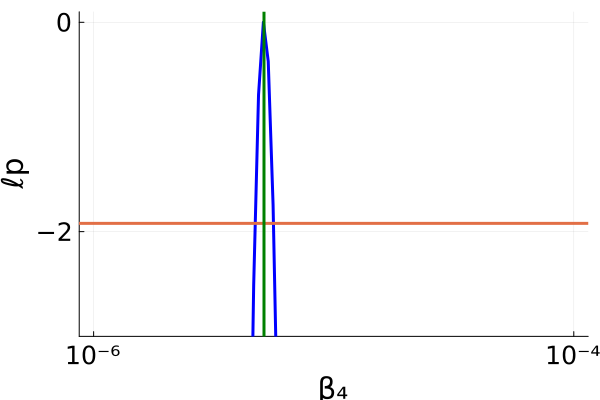

In [37]:
beta_four_range=LinRange(beta_four_min,beta_four_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate4(beta_four_range[i])[1]
end

r2=plot(beta_four_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r2=hline!([llstar],lw=3)
r2=vline!([beta_four_mle],legend=false,xlabel="β₄",ylabel="ℓp",lw=3,color=:green,yticks = [0,-2],xticks = ([beta_four_min,beta_four_max],["10⁻⁶","10⁻⁴"]), xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

In [38]:
function univariate6(α₆)
    a=zeros(2)    
    function fun6(a)
    return loglhood(data,[a[1],a[2],α₆])
    end
    θG=[beta_three_mle,beta_four_mle]
    lb=[beta_three_min,beta_four_min] 
    ub=[beta_three_max,beta_four_max] 
    (xopt,fopt)=Optimise(fun6,θG,lb,ub)
    return fopt,xopt
    end 
    f(x) = univariate6(x)[1]

f (generic function with 1 method)

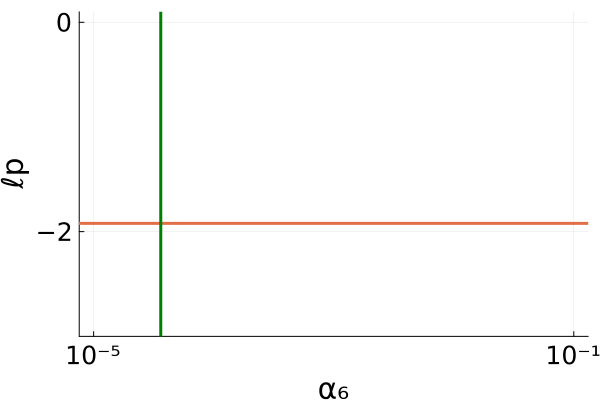

In [39]:
alpha_six_range=LinRange(alpha_six_min,alpha_six_max,M)
ff=zeros(M)
for i in 1:M
    ff[i]=univariate6(alpha_six_range[i])[1]
end

r3=plot(alpha_six_range,ff.-maximum(ff),ylims=(-3,0.1),legend=false,lw=3,color=:blue)
r3=hline!([llstar],lw=3)
r3=vline!([alpha_six_mle],legend=false,xlabel="α₆",ylabel="ℓp",lw=3,color=:green,yticks = [0,-2],xticks = ([alpha_six_min,alpha_six_max],["10⁻⁵","10⁻¹"]),xtickfontsize=17,ytickfontsize=17, xguidefontsize = 20, yguidefontsize = 20, font = "Ariel")

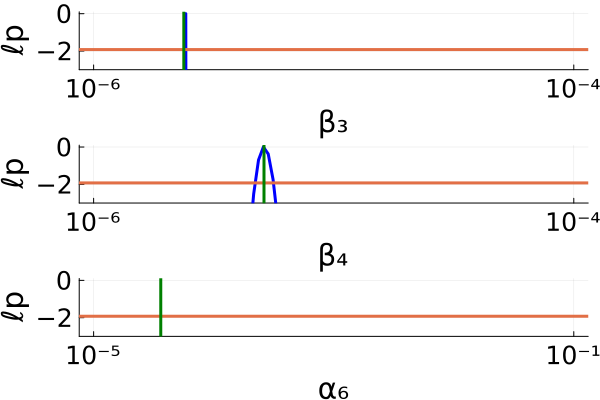

In [40]:
r4=plot(r1,r2,r3,layout=(3,1))
display(r4)